# BIOT 6900 · Module 3 Assignment: Target Triage with Protein Language Models

**Computational Lab 3 · 100 points · due Thursday, October 15 at 6:00 pm**

Apply the Module 3 method to **your own targets from Module 2**, whichever disease you studied. Follow the assignment sheet: each step below matches a numbered step there. Complete every cell marked **TODO**. Helper functions from Part 2 are provided so you can focus on the analysis.

**Before you start:** complete lab Parts 1 and 2; unzip the Module 3 data pack into `data/`; put your Module 2 target file (for example `targets_ad.csv`) next to this notebook.

**Before you submit:** Kernel → Restart & Run All, and check that every cell runs.

In [1]:
# ---------------- YOUR SETTINGS ----------------
from pathlib import Path
ROOT = Path(r"C:\Users\deept\biot6900")
DATA = ROOT / "data"
TARGETS_FILE = ROOT / "module2" / "targets_pdac.csv"
OUT_DIR = ROOT / "Module 3"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DISEASE = "pdac"
TOP_N = 15

GENE_COL = "gene"
SCORE_COL = "score"

SEED = 6900

print("Project root:", ROOT)
print("Data folder:", DATA)
print("Targets file:", TARGETS_FILE)
print("Output folder:", OUT_DIR)

assert ROOT.is_dir(), "ROOT is incorrect."
assert TARGETS_FILE.is_file(), "Cannot find targets_pdac.csv."

Project root: C:\Users\deept\biot6900
Data folder: C:\Users\deept\biot6900\data
Targets file: C:\Users\deept\biot6900\module2\targets_pdac.csv
Output folder: C:\Users\deept\biot6900\Module 3


In [2]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

print("Python executable:", sys.executable)

# ---------------- Check files ----------------

required_files = [ "panel.tsv", "panel_emb_main.npy", "proteome.tsv", "proteome_emb_main.npy", "anchor_variants.tsv", "manifest.json", ]

missing_files = [ filename for filename in required_files if not (DATA / filename).is_file() ]

if missing_files:
    raise FileNotFoundError( f"Missing files in {DATA}: {missing_files}" )

# ---------------- Load tables and embeddings ----------------

panel = pd.read_csv(DATA / "panel.tsv", sep="\t")
proteome = pd.read_csv(DATA / "proteome.tsv", sep="\t")

X_panel = np.load(DATA / "panel_emb_main.npy").astype("float32")
X_prot = np.load(DATA / "proteome_emb_main.npy").astype("float32")

with open(DATA / "manifest.json", encoding="utf-8") as handle:
    manifest = json.load(handle)

# Clean symbols without changing table row order.
for table in [panel, proteome]:
    table["gene"] = ( table["gene"] .astype("string") .str.strip() .str.upper() )

assert X_panel.ndim == 2
assert X_prot.ndim == 2

assert len(panel) == X_panel.shape[0], ( "Panel table and embeddings have different row counts." )
assert len(proteome) == X_prot.shape[0], ( "Proteome table and embeddings have different row counts." )
assert X_panel.shape[1] == X_prot.shape[1], ( "Panel and proteome embeddings have different dimensions." )

assert np.isfinite(X_panel).all(), "Panel embeddings contain invalid values."
assert np.isfinite(X_prot).all(), "Proteome embeddings contain invalid values."

required_panel_columns = { "gene", "family_group", "any_clinical", "sm_clinical", "ab_clinical", }

assert required_panel_columns.issubset(panel.columns), ( f"Missing panel columns: {required_panel_columns - set(panel.columns)}" )

# Convert clinical labels safely to numeric 0/1.
def binary_labels(series):
    cleaned = ( series.astype("string") .str.strip() .str.lower() )

    converted = cleaned.map({ "true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0, })

    if converted.isna().any():
        bad_values = series[converted.isna()].unique()
        raise ValueError(f"Unexpected clinical labels: {bad_values}")

    return converted.astype(int)

for column in ["any_clinical", "sm_clinical", "ab_clinical"]:
    panel[column] = binary_labels(panel[column])

if panel["family_group"].isna().any():
    raise ValueError("Missing family_group values in panel.tsv.")

if manifest.get("dry_run"):
    raise ValueError( "This is a DRY RUN data pack. Obtain the real pack " "before interpreting results biologically." )

print("Panel embeddings:", X_panel.shape)
print("Proteome embeddings:", X_prot.shape)

model_info = manifest.get("embedding_models", {}).get("main", {})
print("Embedding model:", model_info.get("model", "Check manifest.json"))

print("\nPanel columns:")
print(panel.columns.tolist())

print("\nProteome columns:")
print(proteome.columns.tolist())

display(panel.head())
display(proteome.head())

# ---------------- Helper functions ----------------

def make_model():
    return make_pipeline( StandardScaler(), LogisticRegression( C=0.05, max_iter=5000, random_state=SEED, ), )

def evaluate(X, y, groups, folds=5):
    y = np.asarray(y, dtype=int)
    groups = np.asarray(groups)

    if len(y) != len(X) or len(groups) != len(X):
        raise ValueError("Features, labels, and groups must align.")

    if len(np.unique(y)) != 2:
        raise ValueError("Validation needs both positive and negative labels.")

    if np.bincount(y).min() < folds:
        raise ValueError("Too few examples in a class for five-fold validation.")

    if len(np.unique(groups)) < folds:
        raise ValueError("Too few protein families for five-fold validation.")

    random_cv = StratifiedKFold( n_splits=folds, shuffle=True, random_state=SEED, )

    # Explicit split lists also make family separation easy to inspect.
    family_splits = list( GroupKFold(n_splits=folds).split(X, y, groups) )

    for fold_number, (train_idx, test_idx) in enumerate( family_splits, start=1 ):
        train_groups = set(groups[train_idx])
        test_groups = set(groups[test_idx])

        assert train_groups.isdisjoint(test_groups)

        if len(np.unique(y[train_idx])) != 2:
            raise ValueError( f"Family fold {fold_number} has only one training class." )

    random_predictions = cross_val_predict( make_model(), X, y, cv=random_cv, method="predict_proba", )[:, 1]

    family_predictions = cross_val_predict( make_model(), X, y, cv=family_splits, method="predict_proba", )[:, 1]

    return pd.DataFrame( { "AUROC": [ roc_auc_score(y, random_predictions), roc_auc_score(y, family_predictions), ], "Average precision": [ average_precision_score(y, random_predictions), average_precision_score(y, family_predictions), ], }, index=["Random split", "Family split"], )

def fit_prior(X, y):
    y = np.asarray(y, dtype=int)

    if len(np.unique(y)) != 2:
        raise ValueError("Model fitting needs both classes.")

    return make_model().fit(X, y)

def cosine_matrix(A, B):
    norm_A = np.linalg.norm(A, axis=1, keepdims=True)
    norm_B = np.linalg.norm(B, axis=1, keepdims=True)

    if (norm_A == 0).any() or (norm_B == 0).any():
        raise ValueError("A zero embedding cannot have cosine similarity.")

    return (A / norm_A) @ (B / norm_B).T

Python executable: C:\Users\deept\anaconda3\envs\biot6900\python.exe
Panel embeddings: (1201, 960)
Proteome embeddings: (20190, 960)
Embedding model: esmc_300m

Panel columns:
['gene', 'accession', 'length', 'family', 'family_group', 'ensembl_gene', 'sm_clinical', 'ab_clinical', 'any_clinical', 'sm_ligand', 'truncated_main', 'truncated_baseline']

Proteome columns:
['gene', 'accession', 'length', 'family', 'family_group', 'ensembl_gene', 'sequence', 'truncated_main', 'truncated_baseline']


,gene,accession,length,family,family_group,ensembl_gene,sm_clinical,ab_clinical,any_clinical,sm_ligand,truncated_main,truncated_baseline
0,A1CF,Q9NQ94,594,NaN,singleton:Q9NQ94,ENSG00000148584,0,0,0,False,False,False
1,AADACL3,Q5VUY0,407,'GDXG' lipolytic enzyme family,'GDXG' lipolytic enzyme family,ENSG00000188984,0,0,0,False,False,False
2,AARSD1,Q9BTE6,412,"Class-II aminoacyl-tRNA synthetase family, Ala...",Class-II aminoacyl-tRNA synthetase family,ENSG00000108825,0,0,0,False,False,False
3,AATF,Q9NY61,560,AATF family,AATF family,ENSG00000275700,0,0,0,True,False,False
4,ABCB1,P08183,1280,"ABC transporter superfamily, ABCB family, Mult...",ABC transporter superfamily,ENSG00000085563,1,0,1,True,False,True


,gene,accession,length,family,family_group,ensembl_gene,sequence,truncated_main,truncated_baseline
0,A1BG,P04217,495,NaN,singleton:P04217,ENSG00000121410,MSMLVVFLLLWGVTWGPVTEAAIFYETQPSLWAESESLLKPLANVT...,False,False
1,A1CF,Q9NQ94,594,NaN,singleton:Q9NQ94,ENSG00000148584,MESNHKSGDGLSGTQKEAALRALVQRTGYSLVQENGQRKYGGPPPG...,False,False
2,A2M,P01023,1474,Protease inhibitor I39 (alpha-2-macroglobulin)...,Protease inhibitor I39 (alpha-2-macroglobulin)...,ENSG00000175899,MGKNKLLHPSLVLLLLVLLPTDASVSGKPQYMVLVPSLLHTETTEK...,False,True
3,A2ML1,A8K2U0,1454,Protease inhibitor I39 (alpha-2-macroglobulin)...,Protease inhibitor I39 (alpha-2-macroglobulin)...,ENSG00000166535,MWAQLLLGMLALSPAIAEELPNYLVTLPARLNFPSVQKVCLDLSPG...,False,True
4,A3GALT2,U3KPV4,340,Glycosyltransferase 6 family,Glycosyltransferase 6 family,ENSG00000184389,MALKEGLRAWKRIFWRQILLTLGLLGLFLYGLPKFRHLEALIPMGV...,False,False


## Step 1 · Load and map your targets

Keep your top `TOP_N` targets by Module 2 score, then find each gene's row in `proteome.tsv`. **The row number in `proteome.tsv` is the row number in `proteome_emb_main.npy`.** Genes without a reviewed protein (for example non-coding RNAs) will not be found: list them, don't drop them silently.

In [3]:
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

# ---------------- Load Module 2 output ----------------

mine = pd.read_csv(TARGETS_FILE)

mine = mine.rename(columns={GENE_COL: "gene", SCORE_COL: "score",})

if not {"gene", "score"}.issubset(mine.columns):
    raise ValueError("The target file needs gene and score columns.")
    
mine["gene"] = ( mine["gene"] .astype("string") .str.strip() .str.upper() )
mine["score"] = pd.to_numeric(mine["score"], errors="raise")

if mine["gene"].isna().any() or mine["score"].isna().any():
    raise ValueError("The target file contains missing genes or scores.")

if not np.isfinite(mine["score"]).all():
    raise ValueError("The target file contains non-finite scores.")

if mine["gene"].duplicated().any():
    raise ValueError("Duplicate target IDs need to be resolved first.")

top = ( mine.sort_values( "score", ascending=False, kind="mergesort", ) .head(TOP_N) .reset_index(drop=True) .copy() )

# Preserve the original identifiers.
top["original_gene_id"] = top["gene"]
top["week2_original_rank"] = np.arange(1, len(top) + 1)

# Remove version suffixes if present.
top["ensembl_id"] = top["gene"].str.replace(
    r"\.\d+$", "", regex=True
)

print("Original top targets:")
display(top[["original_gene_id", "score"]])

# ---------------- Load a saved ID mapping ----------------

mapping_file = OUT_DIR / "ensembl_symbol_mapping.csv"

if mapping_file.exists():
    mapping_table = pd.read_csv(mapping_file, dtype="string")
    mapping = dict(
        zip(mapping_table["ensembl_id"], mapping_table["gene_symbol"])
    )
else:
    mapping = {}

# ---------------- Resolve Ensembl IDs ----------------

for identifier in top["ensembl_id"]:
    # Existing gene symbols do not need an Ensembl lookup.
    if not identifier.startswith("ENSG"):
        continue

    cached_symbol = mapping.get(identifier)

    if pd.notna(cached_symbol) and str(cached_symbol).strip():
        continue

    url = ( f"https://rest.ensembl.org/lookup/id/{identifier}" "?content-type=application/json" )

    request = Request(
        url,
        headers={"Accept": "application/json"}, )

    try:
        with urlopen(request, timeout=30) as response:
            record = json.load(response)

        symbol = record.get("display_name")

        if not symbol:
            raise ValueError(f"No gene symbol returned for {identifier}.")

        mapping[identifier] = str(symbol).strip().upper()

        # Save after each successful lookup.
        pd.DataFrame(
            [
                {"ensembl_id": key, "gene_symbol": value}
                for key, value in sorted(mapping.items())
            ]
        ).to_csv(mapping_file, index=False)

        print(identifier, "→", mapping[identifier])

    except (HTTPError, URLError, TimeoutError) as error:
        raise RuntimeError(
            f"Ensembl lookup failed for {identifier}: {error}. "
            "This is a mapping/network problem, not proof "
            "that the gene lacks a reviewed protein."
        ) from error

# Replace Ensembl IDs with symbols.
top["gene"] = [
    mapping[identifier]
    if identifier.startswith("ENSG")
    else identifier
    for identifier in top["ensembl_id"]
]

if top["gene"].duplicated().any():
    raise ValueError(
        "Multiple selected IDs map to the same symbol. "
        "Inspect the mapping before continuing."
    )

# ---------------- Map symbols to proteome rows ----------------

# Detect ambiguous mappings rather than silently choosing a protein.
duplicate_proteome_symbols = set(
    proteome.loc[
        proteome["gene"].notna()
        & proteome["gene"].duplicated(keep=False),
        "gene",
    ]
)

ambiguous = sorted(set(top["gene"]) & duplicate_proteome_symbols)

if ambiguous:
    raise ValueError(
        f"Multiple proteome rows exist for {ambiguous}. "
        "Inspect those rows and the Part 2 convention "
        "before selecting a representative protein."
    )

row_of = {
    gene: row
    for row, gene in enumerate(proteome["gene"])
    if pd.notna(gene)
}

top["row"] = top["gene"].map(row_of)

unmapped_table = top.loc[top["row"].isna()].copy()
unmapped = unmapped_table["gene"].tolist()

targets = top.loc[top["row"].notna()].copy()
targets["row"] = targets["row"].astype(int)
targets = targets.reset_index(drop=True)

if targets.empty:
    raise ValueError(
        "No targets mapped. Check gene symbols and proteome columns."
    )

my_genes = targets["gene"].tolist()

top.to_csv(OUT_DIR / "top15_mapping_audit.csv", index=False)
unmapped_table.to_csv(OUT_DIR / "unmapped_targets.csv", index=False)

print(f"Selected: {len(top)}")
print(f"Mapped: {len(targets)}")
print(f"Unmapped: {len(unmapped)}")
print("Unmapped symbols:", unmapped)

display(targets[["original_gene_id", "gene", "score", "row"]])

Original top targets:


,original_gene_id,score
0,ENSG00000181143,0.978723
1,ENSG00000001626,0.978103
2,ENSG00000060718,0.973493
3,ENSG00000170835,0.961968
4,ENSG00000168702,0.956738
5,ENSG00000174672,0.956294
6,ENSG00000115361,0.956294
7,ENSG00000089250,0.955053
8,ENSG00000158125,0.951507
9,ENSG00000171345,0.949557


Selected: 15
Mapped: 15
Unmapped: 0
Unmapped symbols: []


,original_gene_id,gene,score,row
0,ENSG00000181143,MUC16,0.978723,10517
1,ENSG00000001626,CFTR,0.978103,2953
2,ENSG00000060718,COL11A1,0.973493,3397
3,ENSG00000170835,CEL,0.961968,2778
4,ENSG00000168702,LRP1B,0.956738,9307
5,ENSG00000174672,BRSK2,0.956294,1724
6,ENSG00000115361,ACADL,0.956294,124
7,ENSG00000089250,NOS1,0.955053,11173
8,ENSG00000158125,XDH,0.951507,19267
9,ENSG00000171345,KRT19,0.949557,8703


## Step 2 · Guard against leakage

Remove **your own targets** from the training panel before fitting anything, so no target is predicted using its own label.

In [4]:
keep = ~panel["gene"].isin(my_genes).to_numpy()

removed_panel = panel.loc[~keep].copy()

train = panel.loc[keep].reset_index(drop=True)
X_train = X_panel[keep]

assert len(train) == len(X_train)
assert not train["gene"].isin(my_genes).any()

removed_panel.to_csv( OUT_DIR / "removed_training_targets.csv", index=False, )

print("Panel proteins before filtering:", len(panel))
print("Panel proteins removed:", int((~keep).sum()))
print("Panel proteins remaining:", len(train))

if not removed_panel.empty:
    display(removed_panel[["gene", "family_group"]])

Panel proteins before filtering: 1201
Panel proteins removed: 0
Panel proteins remaining: 1201


## Step 3 · Validate your prior

Report family-split AUROC and average precision on the training panel, exactly as in Part 2. This tells your reader how far to trust the numbers that follow.

In [5]:
validation = evaluate( X_train, train["any_clinical"], train["family_group"], folds=5, )

validation.to_csv(OUT_DIR / "validation_metrics.csv")

ap_baseline = train["any_clinical"].mean()

print("Validation results:")
display(validation.round(3))

print(f"Positive-label prevalence / AP baseline: {ap_baseline:.3f}")

Validation results:


,AUROC,Average precision
Random split,0.848,0.727
Family split,0.732,0.548


Positive-label prevalence / AP baseline: 0.334


## Step 4 · Two priors, by modality

Fit one prior on `sm_clinical` (small molecule) and one on `ab_clinical` (antibody), then predict both for your targets using their rows in `X_prot`.

In [6]:
X_targets = X_prot[targets["row"].to_numpy(dtype=int)]

sm_model = fit_prior( X_train, train["sm_clinical"], )

ab_model = fit_prior( X_train, train["ab_clinical"], )

targets["p_sm"] = sm_model.predict_proba(X_targets)[:, 1]
targets["p_ab"] = ab_model.predict_proba(X_targets)[:, 1]

assert targets[["p_sm", "p_ab"]].notna().all().all()

display( targets[["gene", "score", "p_sm", "p_ab"]].round(3) )


,gene,score,p_sm,p_ab
0,MUC16,0.979,0.000,0.151
1,CFTR,0.978,0.044,0.001
2,COL11A1,0.973,0.100,0.000
3,CEL,0.962,0.716,0.009
4,LRP1B,0.957,0.284,0.472
5,BRSK2,0.956,0.267,0.000
6,ACADL,0.956,0.153,0.000
7,NOS1,0.955,0.209,0.001
8,XDH,0.952,0.503,0.003
9,KRT19,0.950,0.011,0.002


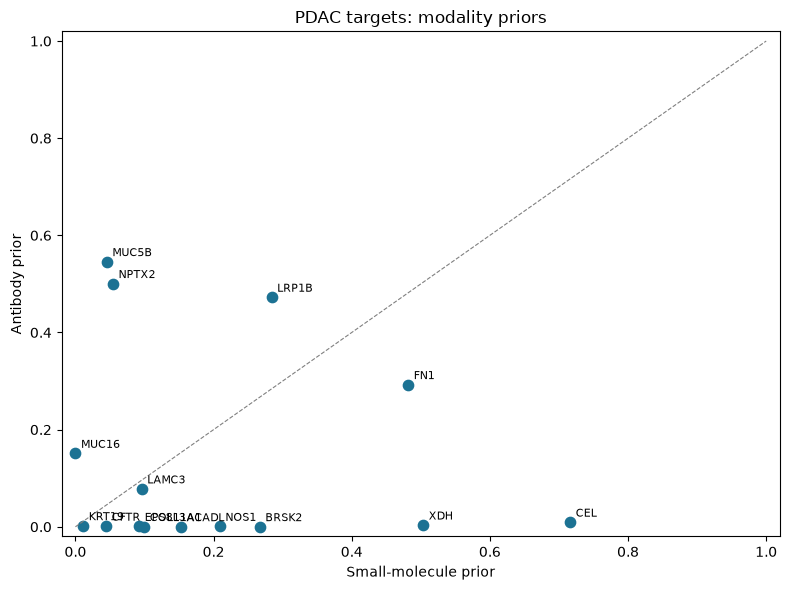

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter( targets["p_sm"], targets["p_ab"], s=55, color="#1C7293", )

for _, row in targets.iterrows():
    ax.annotate( row["gene"], (row["p_sm"], row["p_ab"]), fontsize=8, xytext=(4, 4), textcoords="offset points", )

ax.plot( [0, 1], [0, 1], linestyle="--", color="grey", linewidth=0.8, )

ax.set_xlabel("Small-molecule prior")
ax.set_ylabel("Antibody prior")
ax.set_title("PDAC targets: modality priors")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

fig.tight_layout()
fig.savefig( OUT_DIR / "pdac_modality_map.png", dpi=300, bbox_inches="tight", )

plt.show()

## Step 5 · Nearest known drug targets

For each target, the three most similar training-panel proteins **with clinical precedence**, with cosine similarity. This is the evidence behind each prior.

In [8]:
# Explicit boolean mask is essential.
drugged_mask = train["any_clinical"].eq(1).to_numpy()

drugged = train.loc[drugged_mask].reset_index(drop=True)
X_drugged = X_train[drugged_mask]

if len(drugged) < 3:
    raise ValueError( "Fewer than three clinical-precedence proteins remain." )

S = cosine_matrix(X_targets, X_drugged)

neighbor_text = []
neighbor_records = []

for target_index, target_gene in enumerate(targets["gene"]):
    nearest_indices = np.argsort(-S[target_index])[:3]

    descriptions = []

    for neighbor_rank, neighbor_index in enumerate( nearest_indices, start=1, ):
        neighbor = drugged.iloc[neighbor_index]
        similarity = float(S[target_index, neighbor_index])

        descriptions.append( f"{neighbor['gene']} ({similarity:.3f})" )

        neighbor_records.append({ "target_gene": target_gene, "neighbor_rank": neighbor_rank, "neighbor_gene": neighbor["gene"], "cosine_similarity": similarity, "sm_clinical": int(neighbor["sm_clinical"]), "ab_clinical": int(neighbor["ab_clinical"]), })

    neighbor_text.append("; ".join(descriptions))

targets["nearest_drug_targets"] = neighbor_text

nearest_table = pd.DataFrame(neighbor_records)

nearest_table.to_csv( OUT_DIR / "nearest_drug_targets_detail.csv", index=False, )

display( targets[ ["gene", "p_sm", "p_ab", "nearest_drug_targets"] ].round(3) )


,gene,p_sm,p_ab,nearest_drug_targets
0,MUC16,0.000,0.151,PTHLH (0.891); IL4R (0.855); FGA (0.848)
1,CFTR,0.044,0.001,GUCY2C (0.952); SCN7A (0.947); CASR (0.947)
2,COL11A1,0.100,0.000,COL1A2 (0.951); COL3A1 (0.949); COL4A5 (0.887)
3,CEL,0.716,0.009,GPA33 (0.908); MMP9 (0.907); TNKS2 (0.906)
4,LRP1B,0.284,0.472,ITGA2 (0.956); PLAU (0.952); NRP1 (0.951)
5,BRSK2,0.267,0.000,RARG (0.931); RARB (0.918); SCN4A (0.913)
6,ACADL,0.153,0.000,UMPS (0.931); ADH6 (0.907); ATP4A (0.904)
7,NOS1,0.209,0.001,NOS2 (0.993); MAP3K5 (0.970); NCBP1 (0.970)
8,XDH,0.503,0.003,UMPS (0.958); GPD2 (0.958); LTA4H (0.954)
9,KRT19,0.011,0.002,TNNI2 (0.885); PSMD4 (0.879); TSG101 (0.862)


## Step 6 · Anchor variants (required for everyone)

Report score and within-protein percentile for **APOE R176C (rs7412, ε2)**, **APOE C130R (rs429358, ε4)**, **TREM2 R47H**, and **one p53 hotspot** of your choice. UniProt numbering includes APOE's 18-residue signal peptide (mature names: R158C and C112R).

In [9]:
anchors = pd.read_csv( DATA / "anchor_variants.tsv", sep="\t", )

anchors["gene"] = ( anchors["gene"] .astype("string") .str.strip() .str.upper() )

anchors["variant"] = ( anchors["variant"] .astype("string") .str.strip() )

print("Available variants:")
display(anchors[["gene", "variant", "note"]])

P53_CHOICE = "R175H"

requested_variants = [ ("APOE", "R176C"), ("APOE", "C130R"), ("TREM2", "R47H"), ("TP53", P53_CHOICE), ]

selected_rows = []

for gene, variant in requested_variants:
    match = anchors.loc[ anchors["gene"].eq(gene) & anchors["variant"].eq(variant) ]

    if len(match) != 1:
        raise ValueError( f"Expected one row for {gene} {variant}, " f"but found {len(match)}. " "Check the exact gene/variant names printed above." )

    selected_rows.append(match)

my_anchors = pd.concat( selected_rows, ignore_index=True, )

anchor_output = my_anchors[ ["gene", "variant", "note", "score", "percentile_in_protein"] ]

anchor_output.to_csv( OUT_DIR / "anchor_variant_results.csv", index=False, )

display(anchor_output.round(3))

Available variants:


,gene,variant,note
0,TP53,R175H,hotspot
1,TP53,Y220C,"hotspot, druggable crevice"
2,TP53,G245S,hotspot
3,TP53,R248Q,hotspot
4,TP53,R249S,hotspot
5,TP53,R273H,hotspot
6,TP53,R282W,hotspot
7,APOE,C130R,"rs429358, defines e4 (C112R mature)"
8,APOE,R176C,"rs7412, defines e2 (R158C mature)"
9,TREM2,R47H,"rs75932628, AD risk variant"


,gene,variant,note,score,percentile_in_protein
0,APOE,R176C,"rs7412, defines e2 (R158C mature)",-8.559,11.8
1,APOE,C130R,"rs429358, defines e4 (C112R mature)",7.208,100.0
2,TREM2,R47H,"rs75932628, AD risk variant",-5.156,47.7
3,TP53,R175H,hotspot,-5.974,19.3


## Step 7 · Re-rank and export

Combine your Module 2 evidence with the best-modality tractability prior. Choose the weight `w` (0 = tractability only, 1 = Module 2 only) and **justify it in your report**.

In [10]:
w = 0.6

assert 0 <= w <= 1

# Percentile ranks within the mapped top-target shortlist.
targets["week2_pct"] = targets["score"].rank( pct=True, method="average", )

targets["tract"] = targets[["p_sm", "p_ab"]].max(axis=1)

targets["tract_pct"] = targets["tract"].rank( pct=True, method="average", )

targets["final"] = ( w * targets["week2_pct"] + (1 - w) * targets["tract_pct"] )

# Use original Module 2 position to resolve final-score ties.
targets = ( targets.sort_values( ["final", "week2_original_rank"], ascending=[False, True], kind="mergesort", ) .reset_index(drop=True) )

targets["rank"] = np.arange(1, len(targets) + 1)

out = ( targets.rename(columns={"score": "week2_score"}) [ [ "rank", "gene", "original_gene_id", "week2_score", "p_sm", "p_ab", "nearest_drug_targets", "final", ] ] .copy() )

out_file = OUT_DIR / f"targets_{DISEASE}_w3.csv"

out.to_csv(out_file, index=False)

# Save the full calculation table for traceability.
targets.to_csv( OUT_DIR / "pdac_reranking_details.csv", index=False, )

# Check the written hand-off file.
check = pd.read_csv(out_file)

assert len(check) == len(targets)
assert check["gene"].is_unique
assert check["rank"].tolist() == list(range(1, len(check) + 1))
assert check[["week2_score", "p_sm", "p_ab", "final"]].notna().all().all()

print("Saved:", out_file)
display(out.round(3))

Saved: C:\Users\deept\biot6900\Module 3\targets_pdac_w3.csv


,rank,gene,original_gene_id,week2_score,p_sm,p_ab,nearest_drug_targets,final
0,1,CEL,ENSG00000170835,0.962,0.716,0.009,GPA33 (0.908); MMP9 (0.907); TNKS2 (0.906),0.880
1,2,MUC16,ENSG00000181143,0.979,0.000,0.151,PTHLH (0.891); IL4R (0.855); FGA (0.848),0.760
2,3,LRP1B,ENSG00000168702,0.957,0.284,0.472,ITGA2 (0.956); PLAU (0.952); NRP1 (0.951),0.707
3,4,COL11A1,ENSG00000060718,0.973,0.100,0.000,COL1A2 (0.951); COL3A1 (0.949); COL4A5 (0.887),0.653
4,5,BRSK2,ENSG00000174672,0.956,0.267,0.000,RARG (0.931); RARB (0.918); SCN4A (0.913),0.640
5,6,XDH,ENSG00000158125,0.952,0.503,0.003,UMPS (0.958); GPD2 (0.958); LTA4H (0.954),0.627
6,7,CFTR,ENSG00000001626,0.978,0.044,0.001,GUCY2C (0.952); SCN7A (0.947); CASR (0.947),0.613
7,8,ACADL,ENSG00000115361,0.956,0.153,0.000,UMPS (0.931); ADH6 (0.907); ATP4A (0.904),0.547
8,9,NOS1,ENSG00000089250,0.955,0.209,0.001,NOS2 (0.993); MAP3K5 (0.970); NCBP1 (0.970),0.533
9,10,NPTX2,ENSG00000106236,0.948,0.054,0.501,EPHB4 (0.943); EPHA8 (0.935); FZD1 (0.930),0.520


In [11]:
moved = targets.copy()

# Original position among the selected Module 2 top 15.
moved["week2_rank"] = moved["week2_original_rank"]

# Positive change means the target moved upward.
moved["change"] = moved["week2_rank"] - moved["rank"]
moved["absolute_change"] = moved["change"].abs()

movement_table = ( moved[ [ "gene", "week2_rank", "rank", "change", "p_sm", "p_ab", "tract", "final", "nearest_drug_targets", ] ] .sort_values("rank") )

movement_table.to_csv( OUT_DIR / "ranking_changes.csv", index=False, )

display(movement_table.round(3))

largest_change = moved["absolute_change"].max()

print("\nLargest movement:")
display( moved.loc[ moved["absolute_change"].eq(largest_change), ["gene", "week2_rank", "rank", "change"], ] )


,gene,week2_rank,rank,change,p_sm,p_ab,tract,final,nearest_drug_targets
0,CEL,4,1,3,0.716,0.009,0.716,0.880,GPA33 (0.908); MMP9 (0.907); TNKS2 (0.906)
1,MUC16,1,2,-1,0.000,0.151,0.151,0.760,PTHLH (0.891); IL4R (0.855); FGA (0.848)
2,LRP1B,5,3,2,0.284,0.472,0.472,0.707,ITGA2 (0.956); PLAU (0.952); NRP1 (0.951)
3,COL11A1,3,4,-1,0.100,0.000,0.100,0.653,COL1A2 (0.951); COL3A1 (0.949); COL4A5 (0.887)
4,BRSK2,6,5,1,0.267,0.000,0.267,0.640,RARG (0.931); RARB (0.918); SCN4A (0.913)
5,XDH,9,6,3,0.503,0.003,0.503,0.627,UMPS (0.958); GPD2 (0.958); LTA4H (0.954)
6,CFTR,2,7,-5,0.044,0.001,0.044,0.613,GUCY2C (0.952); SCN7A (0.947); CASR (0.947)
7,ACADL,7,8,-1,0.153,0.000,0.153,0.547,UMPS (0.931); ADH6 (0.907); ATP4A (0.904)
8,NOS1,8,9,-1,0.209,0.001,0.209,0.533,NOS2 (0.993); MAP3K5 (0.970); NCBP1 (0.970)
9,NPTX2,11,10,1,0.054,0.501,0.501,0.520,EPHB4 (0.943); EPHA8 (0.935); FZD1 (0.930)



Largest movement:


,gene,week2_rank,rank,change
6,CFTR,2,7,-5


## Step 8 · Report (3–4 pages, the 40%)

Answer the five questions from the assignment sheet in your report (PDF), using the tables and plots above:

1. **Re-ranking.** Did the prior agree with your Module 2 ranking? Which target moved most, and why? Justify `w`.
2. **Modality.** Pick a target where `p_ab` and `p_sm` differ sharply and explain the biology.
3. **Validation.** Report your family-split metrics (Step 3). Why is this the honest number?
4. **Variants.** Interpret the anchor variant scores (Step 6). Why is a strongly negative score not the same as pathogenic, and what can these models not see?
5. **Limitations and next step.** What can sequence alone not tell you? Which two targets go to Week 4 for structure-based pocket assessment, and why?

Also list any **unmapped** genes from Step 1 and what kind of evidence they would need instead.